# Week 6 – Practice
# Text Vectorization
## Bolohan Constantin and Lefter Sorin
The goal is to practice with pre-trained word embeddings derived with:

1. GloVe (https://nlp.stanford.edu/projects/glove/)
2. word2vec (https://code.google.com/archive/p/word2vec/)

The embeddings should be downloaded from the links above and can be loaded with the `gensim` library in Python. Choose the embeddings having the smallest dimensionality.

In [1]:

%pip -q install gensim scikit-learn scipy matplotlib

import numpy as np
import matplotlib.pyplot as plt
import gensim.downloader as api

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [2]:

glove = api.load("glove-twitter-25")

print("Model: GloVe Twitter 25D")
print("Vocabulary size:", len(glove))
print("Embedding dimensions:", glove.vector_size)


[==================================================] 100.0% 104.8/104.8MB downloaded
Model: GloVe Twitter 25D
Vocabulary size: 1193514
Embedding dimensions: 25


## Task I – Word Embedding Visualization

Visualize a number of 20 words (at your choice) in a 3-dimensional space by:

1. choosing randomly the dimensions
2. by using PCA and tSNE to extract 2- or 3-dimensional embedding

### Task I.1 – Randomly Selected Dimensions (GloVe)

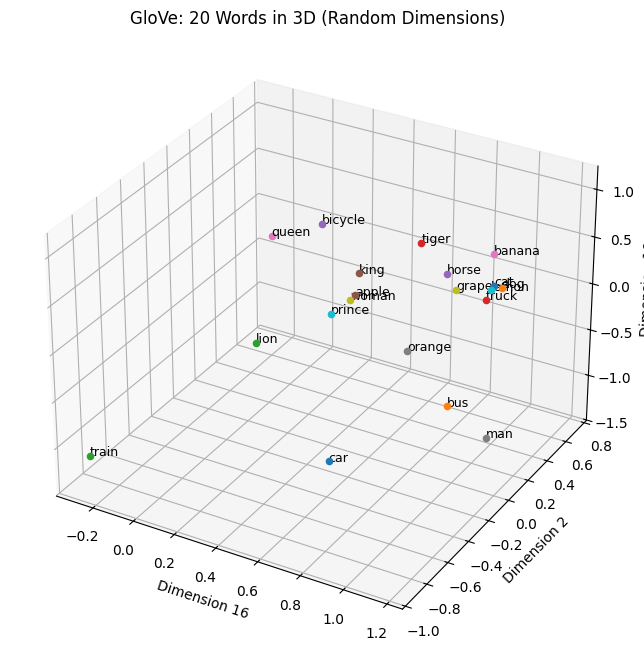

Selected dimensions: [16  2 18]


In [3]:

words = [
    "cat", "dog", "lion", "tiger", "horse",
    "apple", "banana", "orange", "grape", "lemon",
    "car", "bus", "train", "truck", "bicycle",
    "king", "queen", "man", "woman", "prince"
]

assert all(word in glove for word in words), "Some words are missing."

vectors = np.array([glove[word] for word in words])

rng = np.random.default_rng(RANDOM_STATE)
dimensions = rng.choice(glove.vector_size, size=3, replace=False)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

for word, vector in zip(words, vectors):
    x, y, z = vector[dimensions]
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=9)

ax.set_xlabel(f"Dimension {dimensions[0]}")
ax.set_ylabel(f"Dimension {dimensions[1]}")
ax.set_zlabel(f"Dimension {dimensions[2]}")
ax.set_title("GloVe: 20 Words in 3D (Random Dimensions)")

plt.show()

print("Selected dimensions:", dimensions)


### Results and Interpretation – Randomly Selected Dimensions (GloVe)

The 20 words were visualized using randomly selected dimensions **16, 2, and 18**. Some related words, such as *king*, *queen*, and *prince*, appear relatively close, while others, like *car*, *bus*, and *train*, are scattered. This shows that randomly selected dimensions do not reliably preserve semantic relationships, making PCA and t-SNE potentially more suitable for visualization.

### Task I.2 – PCA and t-SNE (GloVe)

**Task Statement:**

Visualize a number of 20 words (at your choice) in a 3-dimensional space by using PCA and tSNE to extract 2- or 3-dimensional embedding.

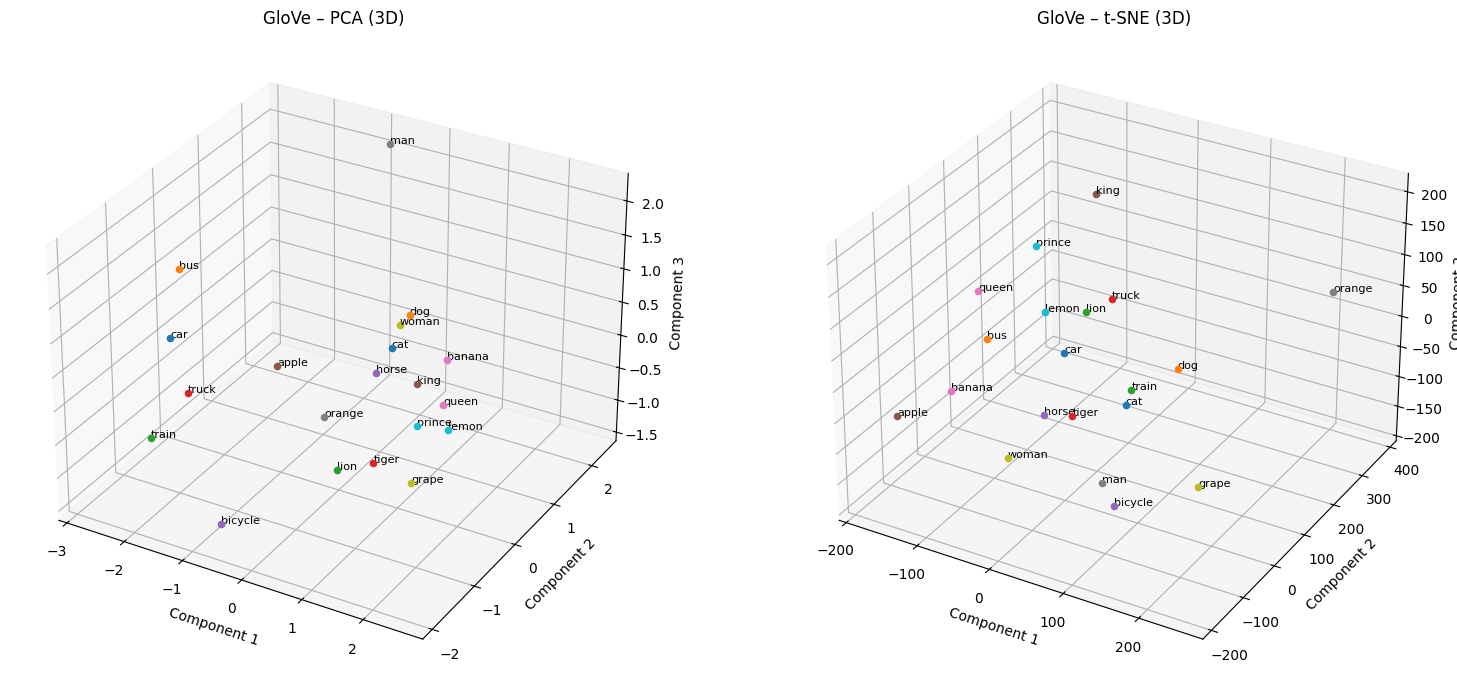

PCA explained variance ratio: [0.2753 0.2126 0.1237]
Total explained variance: 0.6116


In [4]:

pca = PCA(n_components=3)
pca_vectors = pca.fit_transform(vectors)

tsne = TSNE(
    n_components=3,
    perplexity=5,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)
tsne_vectors = tsne.fit_transform(vectors)

fig = plt.figure(figsize=(16, 7))

for i, (data, title) in enumerate([
    (pca_vectors, "PCA"),
    (tsne_vectors, "t-SNE")
], start=1):
    ax = fig.add_subplot(1, 2, i, projection="3d")

    for word, vector in zip(words, data):
        ax.scatter(*vector)
        ax.text(*vector, word, fontsize=8)

    ax.set_title(f"GloVe – {title} (3D)")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.set_zlabel("Component 3")

plt.tight_layout()
plt.show()

print(
    "PCA explained variance ratio:",
    np.round(pca.explained_variance_ratio_, 4)
)
print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)


PCA preserves **61.16% of the total variance** in three dimensions, showing some grouping of related words, such as *cat* and *dog*. t-SNE produces a different distribution, with some related words appearing close together, but no clearly separated semantic clusters. Overall, PCA captures much of the original variance, while t-SNE emphasizes local relationships, although neither perfectly separates the semantic categories.

## Task II – Cosine Similarity (GloVe)

Compute the cosine similarity for 3 pairs of related words (synonyms/antonyms/same semantic field) and 2 pairs of unrelated words.

In [5]:

word_pairs = [
    ("cat", "dog", "Related"),
    ("king", "queen", "Related"),
    ("car", "bus", "Related"),
    ("banana", "train", "Unrelated"),
    ("tiger", "bicycle", "Unrelated")
]

print(f"{'Word 1':<12} {'Word 2':<12} {'Category':<12} {'Similarity':>10}")
print("-" * 50)

for word1, word2, category in word_pairs:
    similarity = glove.similarity(word1, word2)
    print(f"{word1:<12} {word2:<12} {category:<12} {similarity:>10.4f}")


Word 1       Word 2       Category     Similarity
--------------------------------------------------
cat          dog          Related          0.9591
king         queen        Related          0.9202
car          bus          Related          0.8759
banana       train        Unrelated        0.2628
tiger        bicycle      Unrelated        0.7173


### Results and Interpretation – Cosine Similarity (GloVe)

Related word pairs show high cosine similarities: *cat–dog* (0.9591), *king–queen* (0.9202), and *car–bus* (0.8759). The unrelated pair *banana–train* has a much lower similarity (0.2628), while *tiger–bicycle* unexpectedly scores 0.7173. Overall, GloVe captures semantic relationships well for these examples, although some unrelated words also receive relatively high similarity scores.

## Task III – Hierarchical Clustering (GloVe)

Perform hierarchical clustering analysis for a set of ~25 words. Inspect the dendrogram.

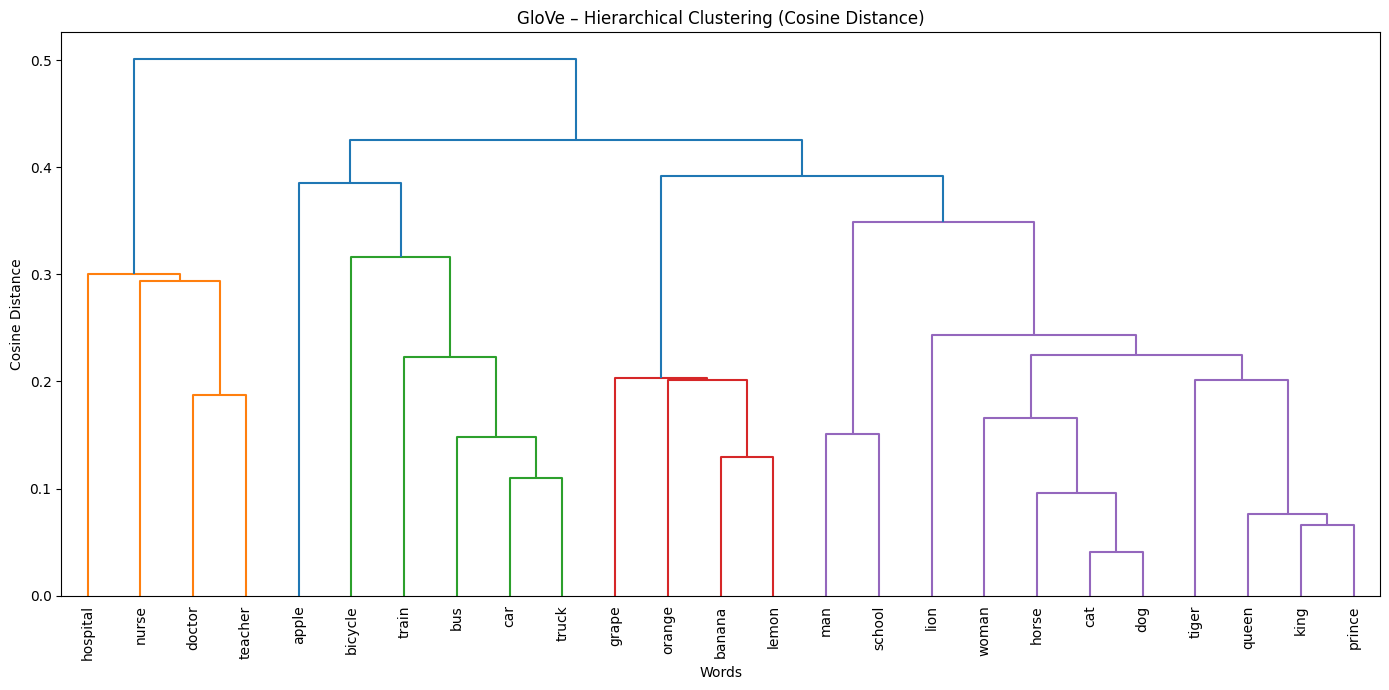

In [8]:

from scipy.spatial.distance import pdist
clustering_words = [
    "cat", "dog", "lion", "tiger", "horse",
    "apple", "banana", "orange", "grape", "lemon",
    "car", "bus", "train", "truck", "bicycle",
    "king", "queen", "man", "woman", "prince",
    "doctor", "nurse", "hospital", "teacher", "school"
]

clustering_vectors = np.array([
    glove[word] for word in clustering_words
])

distances = pdist(clustering_vectors, metric="cosine")
Z = linkage(distances, method="average")

plt.figure(figsize=(14, 7))
dendrogram(
    Z,
    labels=clustering_words,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("GloVe – Hierarchical Clustering (Cosine Distance)")
plt.xlabel("Words")
plt.ylabel("Cosine Distance")
plt.tight_layout()
plt.show()


### Results and Interpretation – Hierarchical Clustering (GloVe)

The dendrogram shows meaningful semantic groups, such as *cat–dog*, *king–queen–prince*, and *car–bus–truck*. Related words generally merge at lower cosine distances, indicating higher similarity. However, some unrelated words appear in the same clusters, showing that GloVe does not perfectly distinguish semantic categories.

# word2vec – Google News 300D

The following experiments repeat Tasks I–III using pre-trained word2vec embeddings to compare their ability to capture semantic relationships with GloVe.

In [9]:

word2vec = api.load("word2vec-google-news-300")

print("Model: word2vec Google News")
print("Vocabulary size:", len(word2vec))
print("Embedding dimensions:", word2vec.vector_size)


[==================================================] 100.0% 1662.8/1662.8MB downloaded
Model: word2vec Google News
Vocabulary size: 3000000
Embedding dimensions: 300


## Task I – Word Embedding Visualization (word2vec)

Visualize a number of 20 words (at your choice) in a 3-dimensional space by:

1. choosing randomly the dimensions
2. by using PCA and tSNE to extract 2- or 3-dimensional embedding

### Task I.1 – Randomly Selected Dimensions

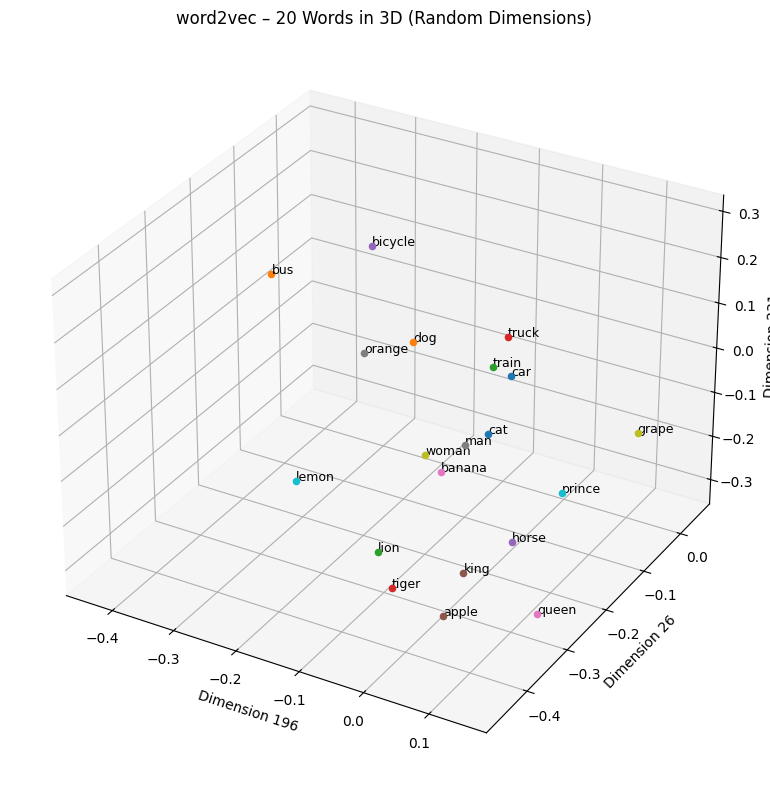

Selected dimensions: [196  26 231]


In [10]:

assert all(word in word2vec for word in words), "Some words are missing."

w2v_vectors = np.array([word2vec[word] for word in words])

rng = np.random.default_rng(RANDOM_STATE)
w2v_dimensions = rng.choice(
    word2vec.vector_size, size=3, replace=False
)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

for word, vector in zip(words, w2v_vectors):
    x, y, z = vector[w2v_dimensions]
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=9)

ax.set_xlabel(f"Dimension {w2v_dimensions[0]}")
ax.set_ylabel(f"Dimension {w2v_dimensions[1]}")
ax.set_zlabel(f"Dimension {w2v_dimensions[2]}")
ax.set_title("word2vec – 20 Words in 3D (Random Dimensions)")

plt.tight_layout()
plt.show()

print("Selected dimensions:", w2v_dimensions)


### Results and Interpretation – Randomly Selected Dimensions (word2vec)

The 20 words were visualized using randomly selected dimensions **196, 26, and 3**. Some related words, such as *car–train* and *lion–tiger*, appear relatively close, while others are scattered. Similar to GloVe, randomly selected dimensions do not consistently preserve semantic relationships, making dimensionality reduction techniques more suitable for visualization.

### Task I.2 – PCA and t-SNE (word2vec)

Visualize a number of 20 words in a 3-dimensional space by using PCA and tSNE to extract 2- or 3-dimensional embedding.

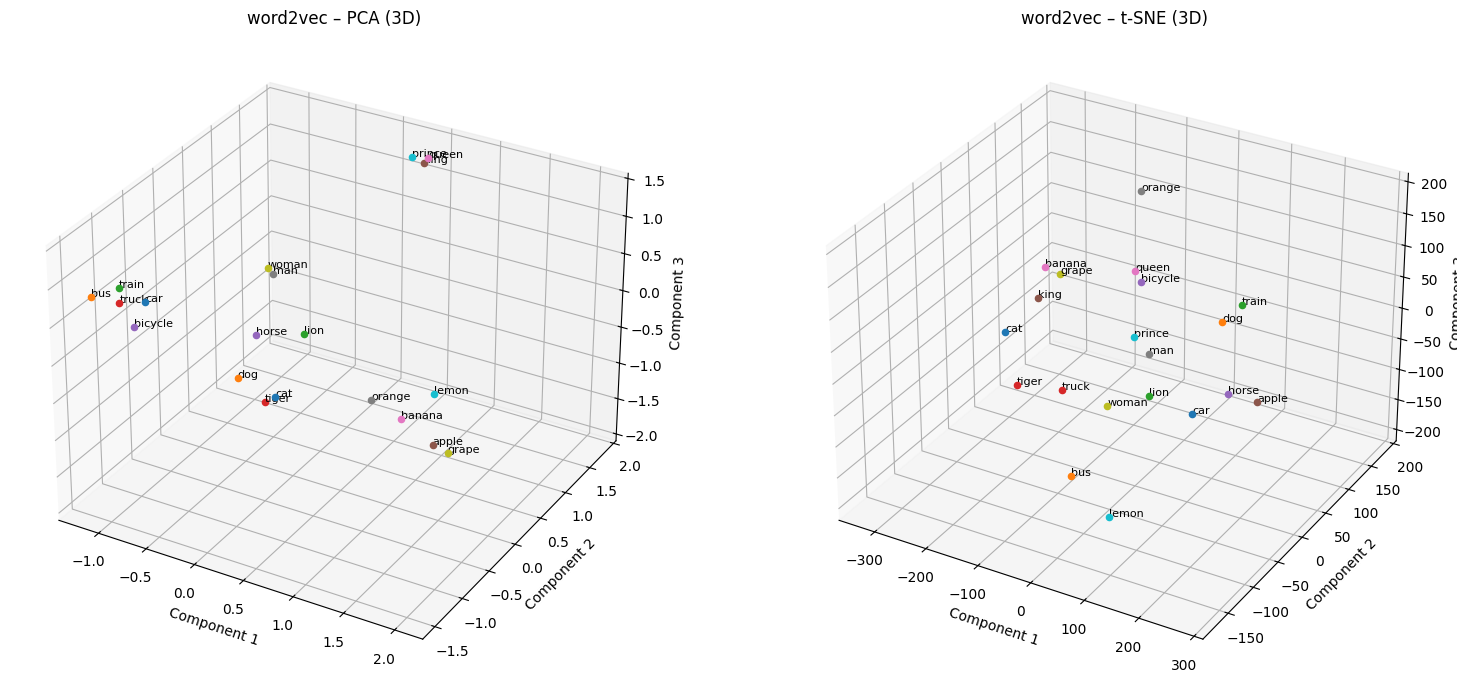

PCA explained variance ratio: [0.1625 0.1542 0.123 ]
Total explained variance: 0.4397


In [11]:

w2v_pca = PCA(n_components=3)
w2v_pca_vectors = w2v_pca.fit_transform(w2v_vectors)

w2v_tsne = TSNE(
    n_components=3,
    perplexity=5,
    random_state=RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)
w2v_tsne_vectors = w2v_tsne.fit_transform(w2v_vectors)

fig = plt.figure(figsize=(16, 7))

for i, (data, title) in enumerate([
    (w2v_pca_vectors, "PCA"),
    (w2v_tsne_vectors, "t-SNE")
], start=1):
    ax = fig.add_subplot(1, 2, i, projection="3d")

    for word, vector in zip(words, data):
        ax.scatter(*vector)
        ax.text(*vector, word, fontsize=8)

    ax.set_title(f"word2vec – {title} (3D)")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.set_zlabel("Component 3")

plt.tight_layout()
plt.show()

print(
    "PCA explained variance ratio:",
    np.round(w2v_pca.explained_variance_ratio_, 4)
)
print(
    "Total explained variance:",
    round(w2v_pca.explained_variance_ratio_.sum(), 4)
)


### Results and Interpretation – PCA and t-SNE (word2vec)

PCA preserves **43.97% of the total variance**, showing relatively clear semantic groups, particularly for transportation and fruits. t-SNE produces a more scattered distribution, with less consistent semantic grouping. Compared to GloVe (61.16%), word2vec retains less variance in three PCA components, although this does not necessarily indicate lower embedding quality.

## Task II – Cosine Similarity (word2vec)

Compute the cosine similarity for 3 pairs of related words (synonyms/antonyms/same semantic field) and 2 pairs of unrelated words.

In [12]:

print(f"{'Word 1':<12} {'Word 2':<12} {'Category':<12} {'Similarity':>10}")
print("-" * 50)

for word1, word2, category in word_pairs:
    similarity = word2vec.similarity(word1, word2)
    print(f"{word1:<12} {word2:<12} {category:<12} {similarity:>10.4f}")


Word 1       Word 2       Category     Similarity
--------------------------------------------------
cat          dog          Related          0.7609
king         queen        Related          0.6511
car          bus          Related          0.4693
banana       train        Unrelated        0.0620
tiger        bicycle      Unrelated        0.2090


### Results and Interpretation – Cosine Similarity (word2vec)

Related pairs show higher similarities: *cat–dog* (0.7609), *king–queen* (0.6511), and *car–bus* (0.4693). Unrelated pairs have much lower scores: *banana–train* (0.0620) and *tiger–bicycle* (0.2090). Compared to GloVe, word2vec provides a clearer separation between related and unrelated words in these examples.

## Task III – Hierarchical Clustering (word2vec)

Perform hierarchical clustering analysis for a set of ~25 words. Inspect the dendrogram.

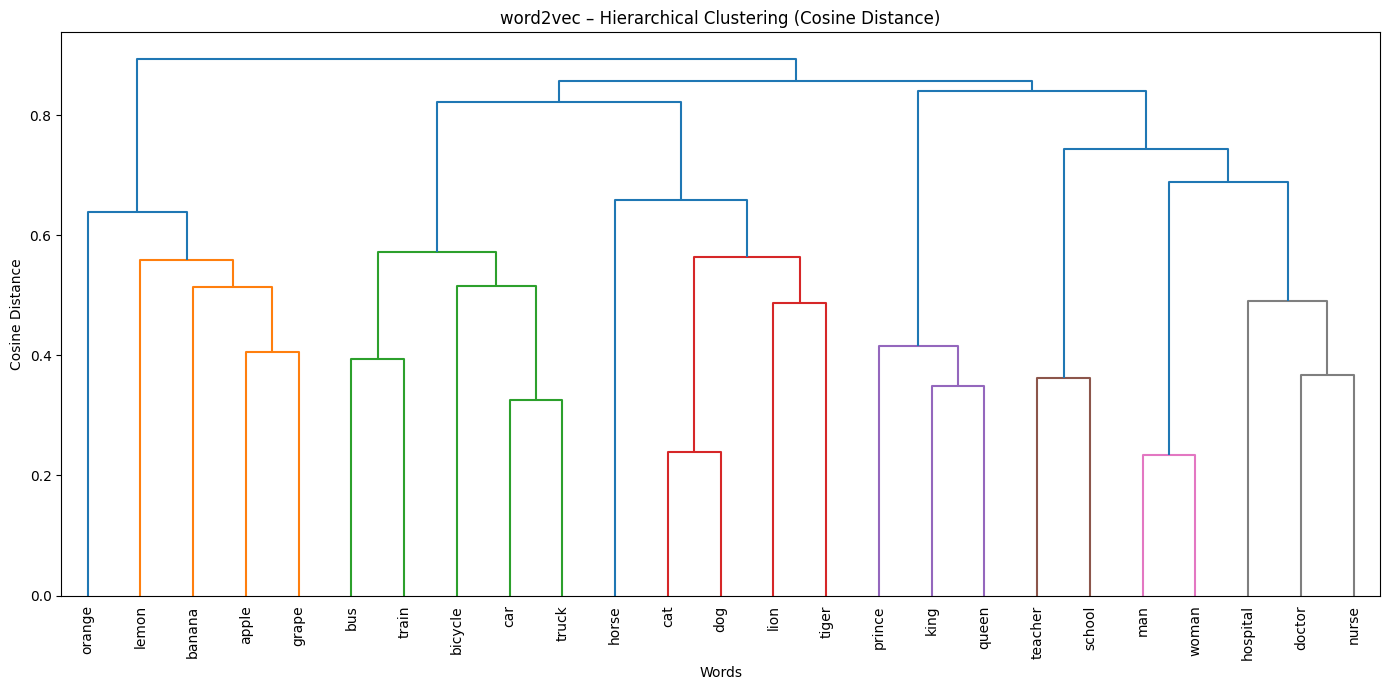

In [13]:

w2v_clustering_vectors = np.array([
    word2vec[word] for word in clustering_words
])

w2v_distances = pdist(w2v_clustering_vectors, metric="cosine")
w2v_Z = linkage(w2v_distances, method="average")

plt.figure(figsize=(14, 7))
dendrogram(
    w2v_Z,
    labels=clustering_words,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("word2vec – Hierarchical Clustering (Cosine Distance)")
plt.xlabel("Words")
plt.ylabel("Cosine Distance")
plt.tight_layout()
plt.show()


### Results and Interpretation – Hierarchical Clustering (word2vec)

The dendrogram shows clear semantic clusters, including fruits (*apple, grape, banana*), transportation (*car, truck, bus*), and animals (*cat, dog, lion, tiger*). Related words generally merge at lower cosine distances, while unrelated groups remain more separated. Compared to GloVe, word2vec produces more distinct and semantically consistent clusters for these selected words.

## Final Comparison and Conclusions

Both GloVe and word2vec successfully capture semantic relationships between words, but their performance differs across the experiments.

GloVe generally produces higher cosine similarity scores, including for unrelated words, while word2vec shows a clearer distinction between related and unrelated pairs. Hierarchical clustering also reveals more consistent semantic groups with word2vec.

PCA preserves 61.16% of the variance for GloVe and 43.97% for word2vec, although these percentages cannot directly determine which model is better.

**Overall, word2vec demonstrates better semantic separation for the selected words in these experiments.** However, this conclusion is limited to the tested examples, and the differences in training data and embedding dimensionality prevent a fully controlled comparison.